# HSA_Cam_B_002.py
 This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.
 HSA_Cam_B_002.py is the model
## First try to actually infer the model

### Plan:
* generate data
* instantiate the model
* infer the model
* check HDIs
* select next experiment at highest HDI

### Results:
* Inference works
* HDIs work
* max HDI strategy does not work

In [147]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize

pytensor.config.mode = "JAX"

In [148]:
from HSA_Cam_B_002 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

In [149]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T


def post_model_over_p(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.linspace(4, 20, 100).reshape(-1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(-1, 5),
        "T": jnp.array(proposal[0]).reshape(1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_p(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.linspace(4, 20, 100).reshape(-1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(-1, 5),
        jnp.array(proposal[0]).reshape(1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [150]:
T = jnp.array([560, 570, 580], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([4, 5, 6], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([1], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([1000], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([0.5], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 0.05 * r
print(r_obs)

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [1.24968760e+00 1.24968760e+00 0.00000000e+00 1.24968760e-03
  2.49937519e+00]
 [1.49962512e+00 1.49962512e+00 0.00000000e+00 1.49962512e-03
  2.99925023e+00]]
[[7.61192633e-05]
 [1.16399861e-04]
 [1.72598760e-04]]
[[7.97627391e-05]
 [1.10754881e-04]
 [1.81289681e-04]]


In [151]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    rel_HDI = HDI / jnp.median(res)
    return -rel_HDI

In [152]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [153]:
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\jax\linker.py:32: UserWarning: The RandomType SharedVariables [RNG(<Generator(PCG64) at 0x2821FA43A00>), RNG(<Generator(PCG64) at 0x282130DBD80>), RNG(<Generator(PCG64) at 0x2821FA43680>), RNG(<Generator(PCG64) at 0x2821FA426C0>), RNG(<Generator(PCG64) at 0x282130DBE60>), RNG(<Generator(PCG64) at 0x282136F8C80>), RNG(<Generator(PCG64) at 0x2821FA43060>), RNG(<Generator(PCG64) at 0x282130DACE0>), RNG(<Generator(PCG64) at 0x282130DB060>), RNG(<Generator(PCG64) at 0x282130DBAE0>)] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]


Do not use the maximisation technique. Use only sampling.

In [154]:
# sol = minimize(
#     max_func,
#     jnp.array([555.0, 15.0, 0.5, 1000.0, 0.5]),
#     args=(prior_idata, "prior"),
#     bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
#     method="Nelder-Mead",
# )
# proposals = np.atleast_2d(sol.x)
# print(proposals)

proposals = np.array(
    [
        [500.0, 4.0, 1.0, 1000.0, 0.5],
        [500.0, 20.0, 1.0, 1000.0, 0.5],
        # [550.0, 4.0, 1.0, 1000.0, 0.5],
        [600.0, 4.0, 1.0, 1000.0, 0.5],
        [600.0, 20.0, 1.0, 1000.0, 0.5],
    ]
)

In [155]:
Ts = jnp.linspace(500, 600, 100)
test_res = post_model_over_T(proposals[0], prior_idata, key="prior")
true_res = true_model_over_T(proposals[0])

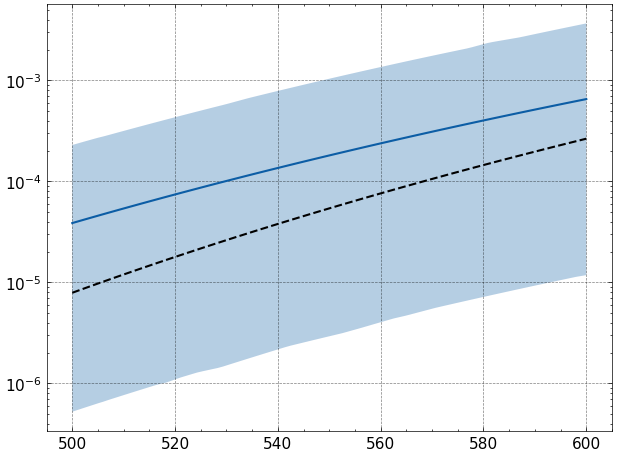

In [156]:
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(Ts, true_res.squeeze(), color="black", linestyle="dashed")
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
plt.yscale("log")

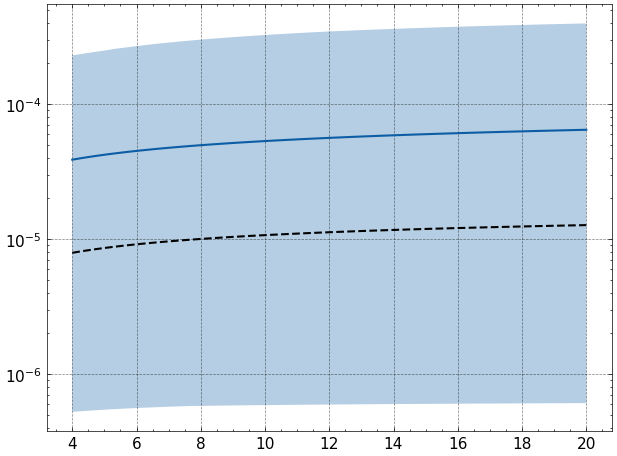

In [157]:
ps = jnp.linspace(4, 20, 100)
test_res = post_model_over_p(proposals[0], prior_idata, key="prior")
true_res = true_model_over_p(proposals[0])

plt.plot(ps, test_res.mean(axis=1))
plt.plot(ps, true_res.squeeze(), color="black", linestyle="dashed")
plt.fill_between(
    x=ps,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
plt.yscale("log")

# First Conditioning step

In [158]:
T = jnp.array([proposals[:, 0]], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([proposals[:, 1]], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([proposals[:, 2]], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([proposals[:, 3]], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([proposals[:, 4]], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 0.05 * r

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [4.99875039e+00 4.99875039e+00 0.00000000e+00 4.99875039e-03
  9.99750078e+00]
 [9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [4.99875039e+00 4.99875039e+00 0.00000000e+00 4.99875039e-03
  9.99750078e+00]]


In [159]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [160]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 263 seconds.
There were 544 divergences after tuning. Increase `target_accept` or reparameterize.


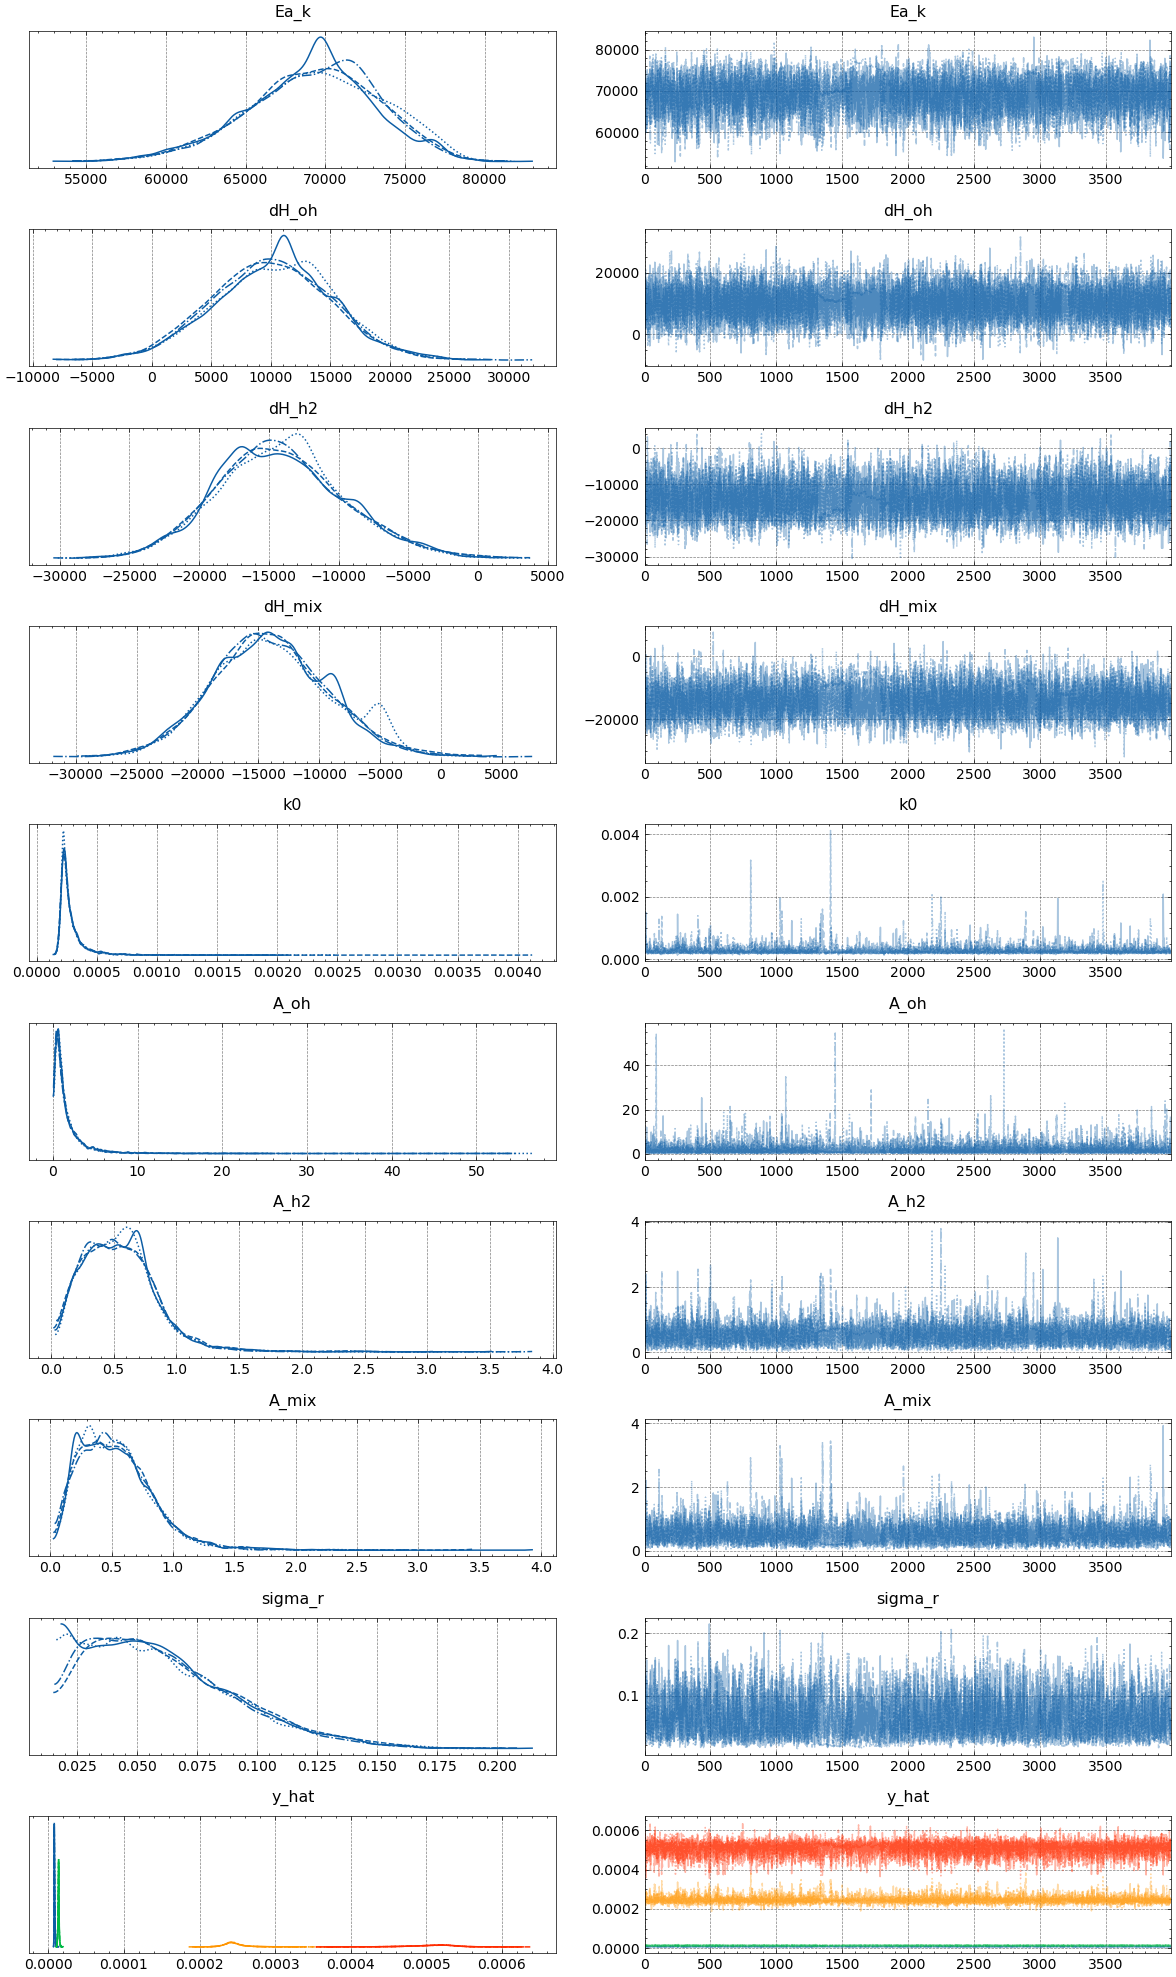

In [174]:
import arviz as az

az.plot_trace(idata, divergences=False)
plt.show()

In [168]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res_T = true_model_over_T(proposals[3])

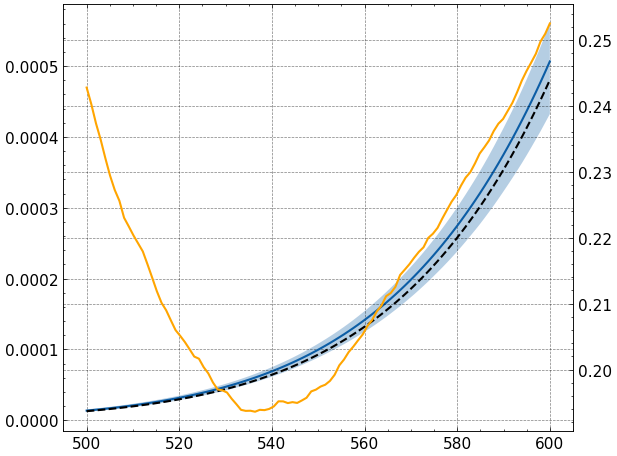

In [169]:
plt.plot(
    Ts,
    test_res.mean(axis=1),
)
plt.plot(
    Ts,
    true_res_T.squeeze(),
    color="black",
    linestyle="--",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
    / np.mean(test_res, axis=1),
    color="orange",
)

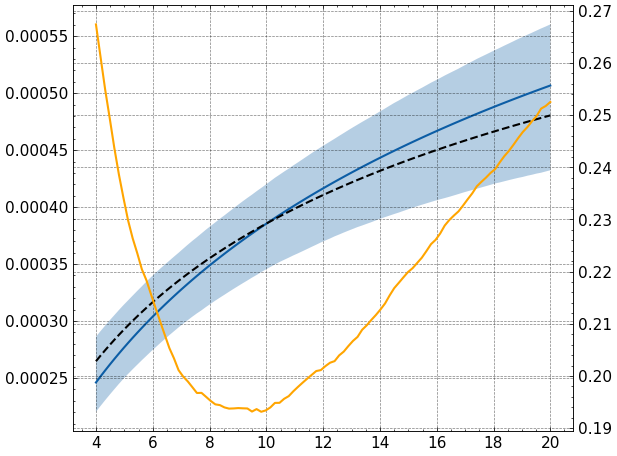

In [173]:
test_res = post_model_over_p(proposals[2], idata, key="posterior")
true_res = true_model_over_p(proposals[2])
plt.plot(
    ps,
    test_res.mean(axis=1),
)
plt.plot(
    ps,
    true_res.squeeze(),
    color="black",
    linestyle="--",
)
plt.fill_between(
    x=ps,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    ps,
    (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
    / np.mean(test_res, axis=1),
    color="orange",
)
plt.show()

In [28]:
# sol = minimize(
#     max_func,
#     jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
#     args=(idata, "posterior"),
#     bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
#     method="Nelder-Mead",
# )
# # proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
# print(sol.x)

[6.e+02 2.e+01 5.e-01 1.e+03 1.e+00]


In [95]:
proposals = np.concatenate(
    (
        proposals,
        np.array(
            [
                # [500.0, 10.0, 1.0, 1000.0, 0.5],
                # [550.0, 10.0, 1.0, 1000.0, 0.5],
                # [600.0, 10.0, 1.0, 1000.0, 0.5],
                [500.0, 20.0, 1.0, 1000.0, 0.5],
                # [550.0, 20.0, 1.0, 1000.0, 0.5],
                [600.0, 20.0, 1.0, 1000.0, 0.5],
            ]
        ),
    ),
    axis=0,
)

In [96]:
print(proposals)

[[5.e+02 4.e+00 1.e+00 1.e+03 5.e-01]
 [6.e+02 4.e+00 1.e+00 1.e+03 5.e-01]
 [5.e+02 2.e+01 1.e+00 1.e+03 5.e-01]
 [6.e+02 2.e+01 1.e+00 1.e+03 5.e-01]]


In [100]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res_T = true_model_over_T(proposals[3])

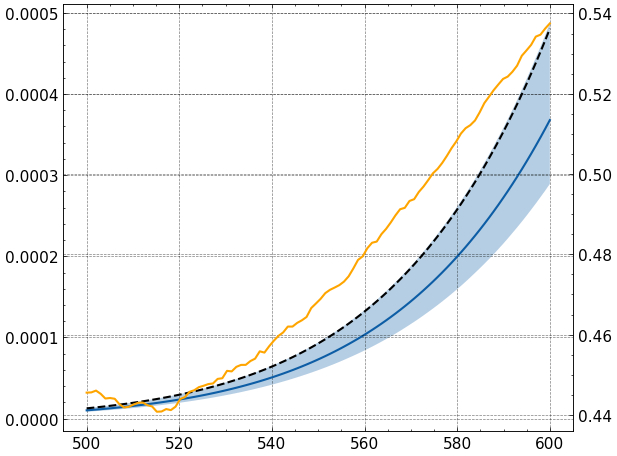

In [101]:
plt.plot(
    Ts,
    test_res.mean(axis=1),
)
plt.plot(
    Ts,
    true_res_T.squeeze(),
    color="black",
    linestyle="--",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
    / np.mean(test_res, axis=1),
    color="orange",
)

# Second Sampling step

In [102]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 0.05 * r
print(r_obs.shape)

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [4.99875039e+00 4.99875039e+00 0.00000000e+00 4.99875039e-03
  9.99750078e+00]
 [4.99875039e+00 4.99875039e+00 0.00000000e+00 4.99875039e-03
  9.99750078e+00]]
(4, 1)


In [103]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [104]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 189 seconds.
There were 774 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


array([[<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

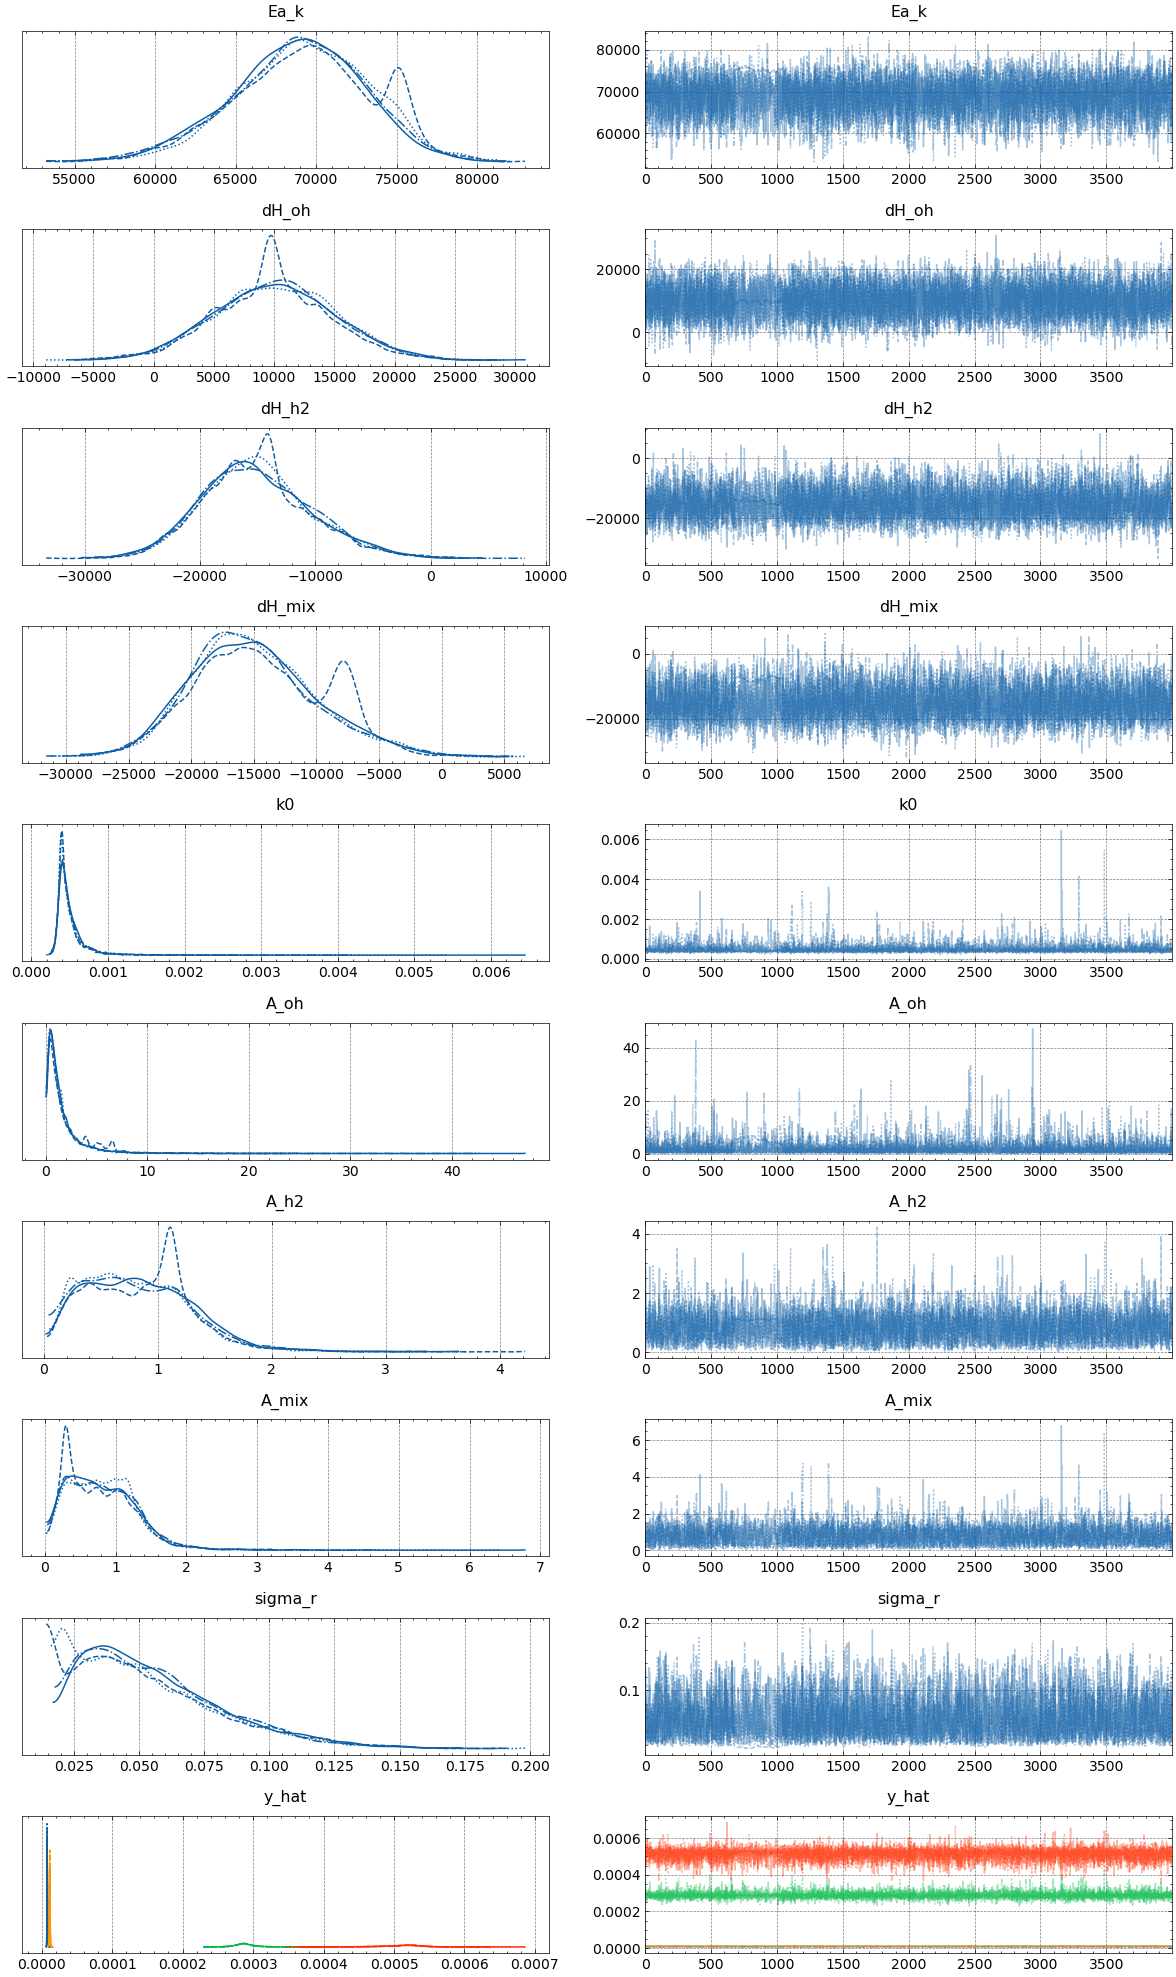

In [105]:
az.plot_trace(idata, divergences=False)

In [71]:
# get relative ESS
az.ess(idata)

<xarray.Dataset> Size: 224B
Dimensions:      (y_hat_dim_0: 9, y_hat_dim_1: 1)
Coordinates:
  * y_hat_dim_0  (y_hat_dim_0) int64 72B 0 1 2 3 4 5 6 7 8
  * y_hat_dim_1  (y_hat_dim_1) int64 8B 0
Data variables:
    Ea_k         float64 8B 6.23e+03
    dH_oh        float64 8B 1.478e+04
    dH_h2        float64 8B 7.792e+03
    dH_mix       float64 8B 7.187e+03
    k0           float64 8B 9.728e+03
    A_oh         float64 8B 1.371e+04
    A_h2         float64 8B 5.595e+03
    A_mix        float64 8B 5.671e+03
    sigma_r      float64 8B 3.395e+03
    y_hat        (y_hat_dim_0, y_hat_dim_1) float64 72B 1.017e+04 ... 1.244e+04

In [110]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res = true_model_over_T(proposals[3])

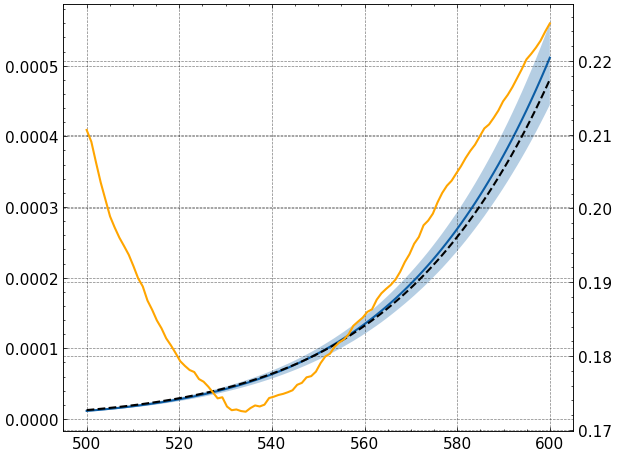

In [111]:
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
    / np.mean(test_res, axis=1),
    color="orange",
)

In [30]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+00, 5.00000000e-01, 7.72568198e+02,
        3.89163042e-01]])

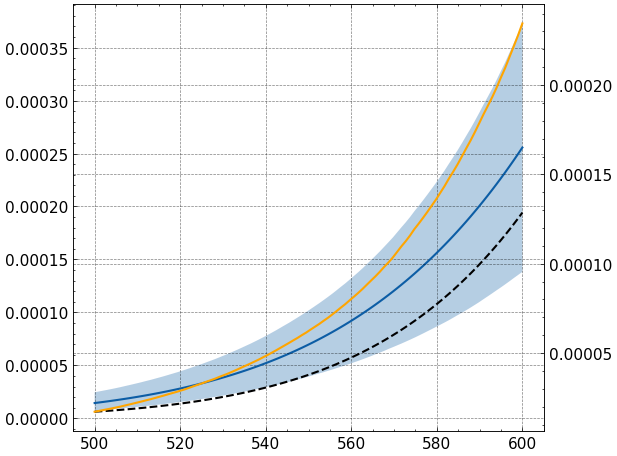

In [31]:
test_res = post_model_over_T(proposals[2], idata, key="posterior")
true_res = true_model_over_T(proposals[2])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

# third conditioning step

In [32]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 0.05 * r
print(r_obs.shape)

[[4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]
 [7.99680173e+00 3.99840087e+00 0.00000000e+00 7.99680173e-03
  7.99680173e+00]
 [3.59007686e-01 7.18015373e-01 0.00000000e+00 4.64693858e-04
  9.22512271e-01]]
(3, 1)


In [33]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [34]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 90 seconds.
There were 1013 divergences after tuning. Increase `target_accept` or reparameterize.


array([[<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

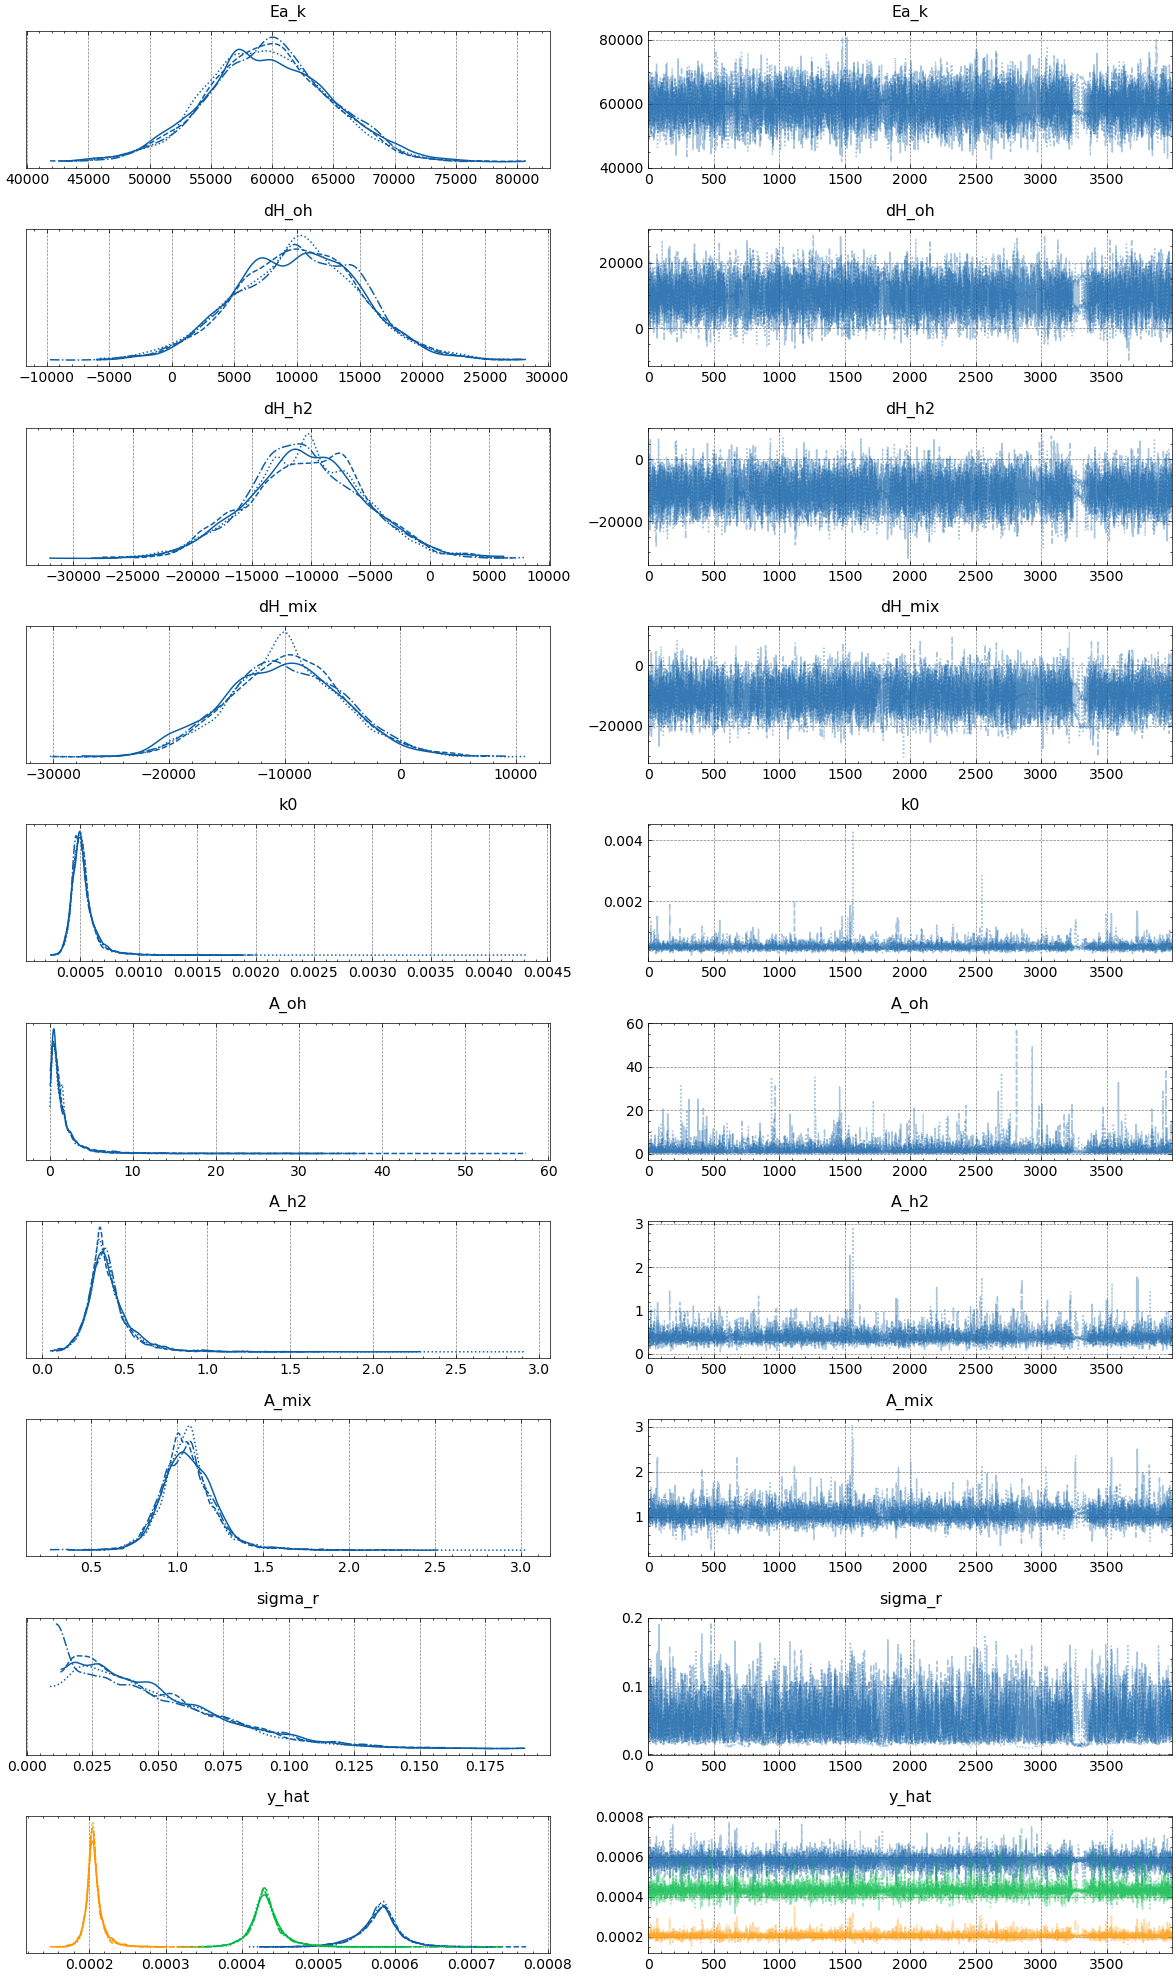

In [35]:
az.plot_trace(idata, divergences=False)

In [36]:
test_res = post_model_over_T(proposals[2], idata, key="posterior")
true_res = true_model_over_T(proposals[2])

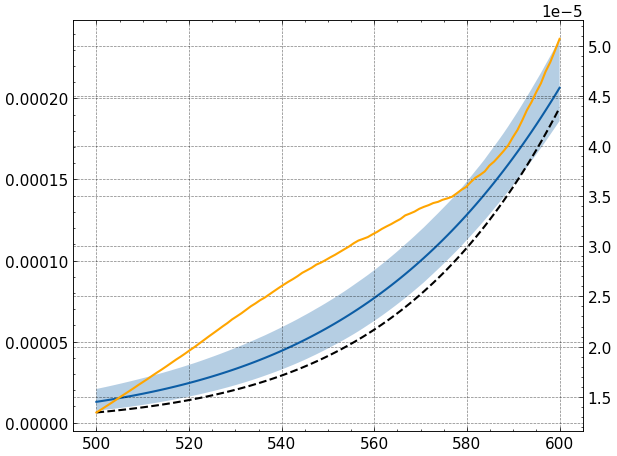

In [37]:
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [38]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+00, 5.00000000e-01, 7.72568198e+02,
        3.89163042e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00]])

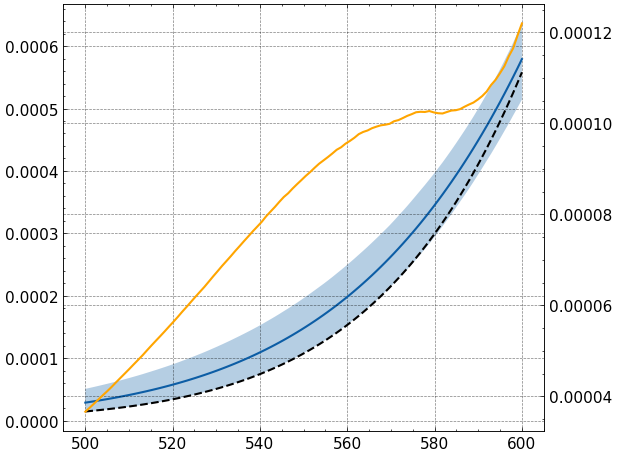

In [39]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res = true_model_over_T(proposals[3])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

# Fourth Conditioning Step

In [40]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 0.05 * r
print(r_obs.shape)

[[4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]
 [7.99680173e+00 3.99840087e+00 0.00000000e+00 7.99680173e-03
  7.99680173e+00]
 [3.59007686e-01 7.18015373e-01 0.00000000e+00 4.64693858e-04
  9.22512271e-01]
 [4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]]
(4, 1)


In [41]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [42]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 74 seconds.
There were 39 divergences after tuning. Increase `target_accept` or reparameterize.


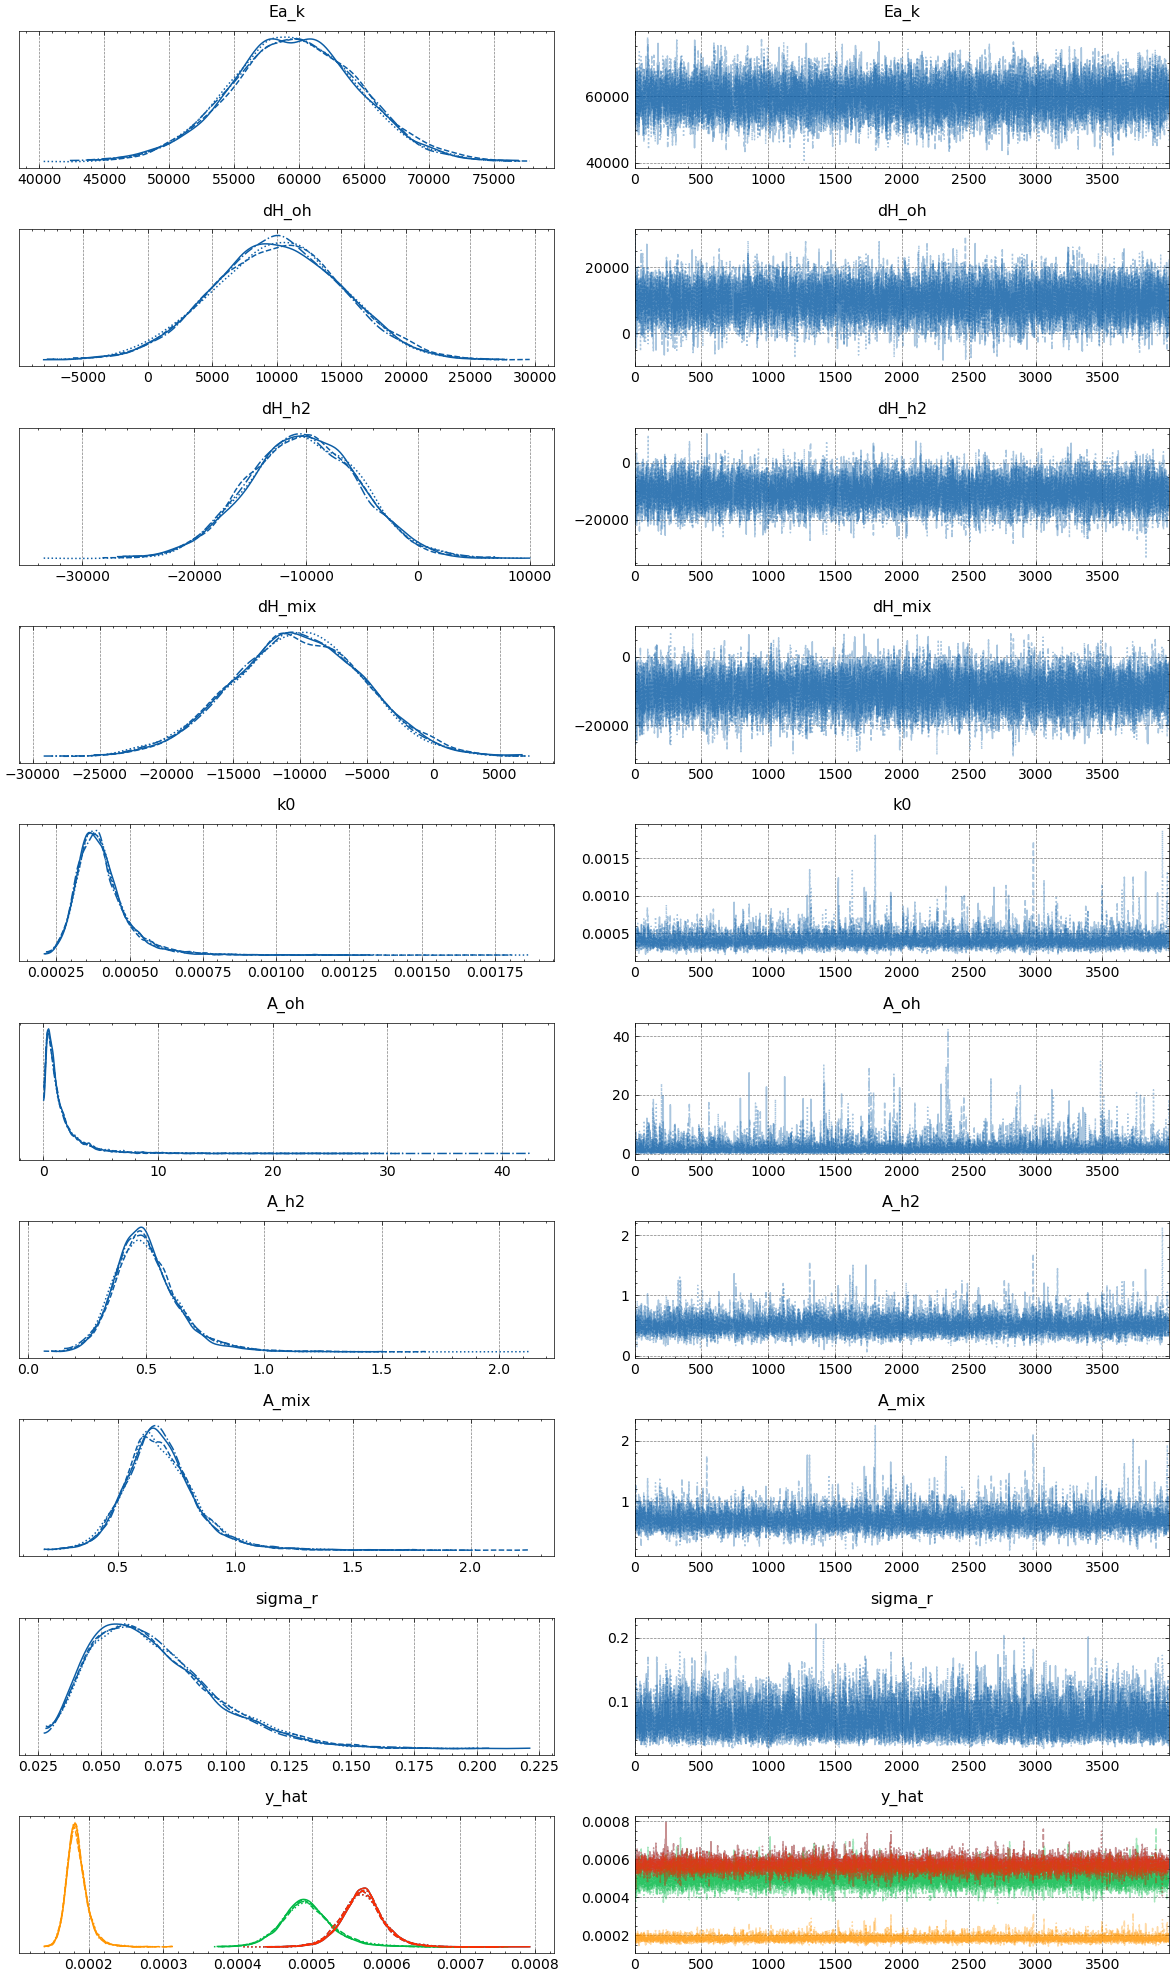

In [43]:
az.plot_trace(idata, divergences=False)
plt.show()

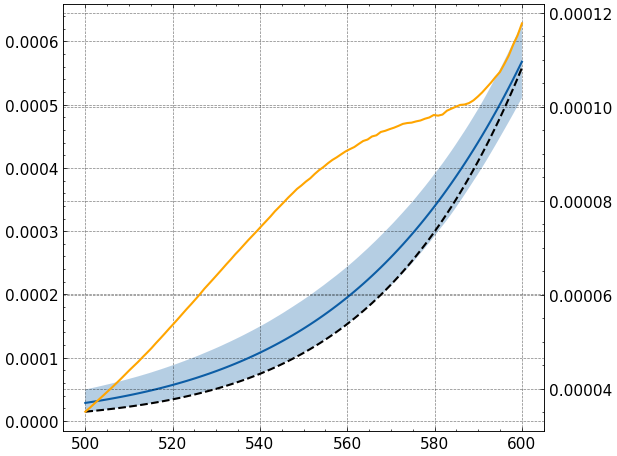

In [44]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res = true_model_over_T(proposals[3])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [45]:
sol = minimize(
    max_func,
    jnp.array([555.0, 10.0, 1.0, 100, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+00, 5.00000000e-01, 7.72568198e+02,
        3.89163042e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00]])

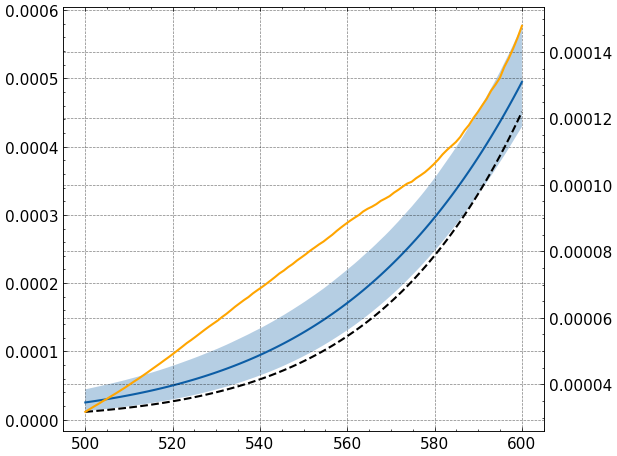

In [46]:
test_res = post_model_over_T(proposals[4], idata, key="posterior")
true_res = true_model_over_T(proposals[4])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

# Fifth Sampling Step

In [47]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 0.05 * r
print(r_obs)

[[0.00055803]
 [0.00045083]
 [0.00019423]
 [0.00055803]
 [0.00045083]]
[[0.00057731]
 [0.00043984]
 [0.00018301]
 [0.00056141]
 [0.00044641]]


In [48]:
with model:
    idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 72 seconds.
There were 31 divergences after tuning. Increase `target_accept` or reparameterize.


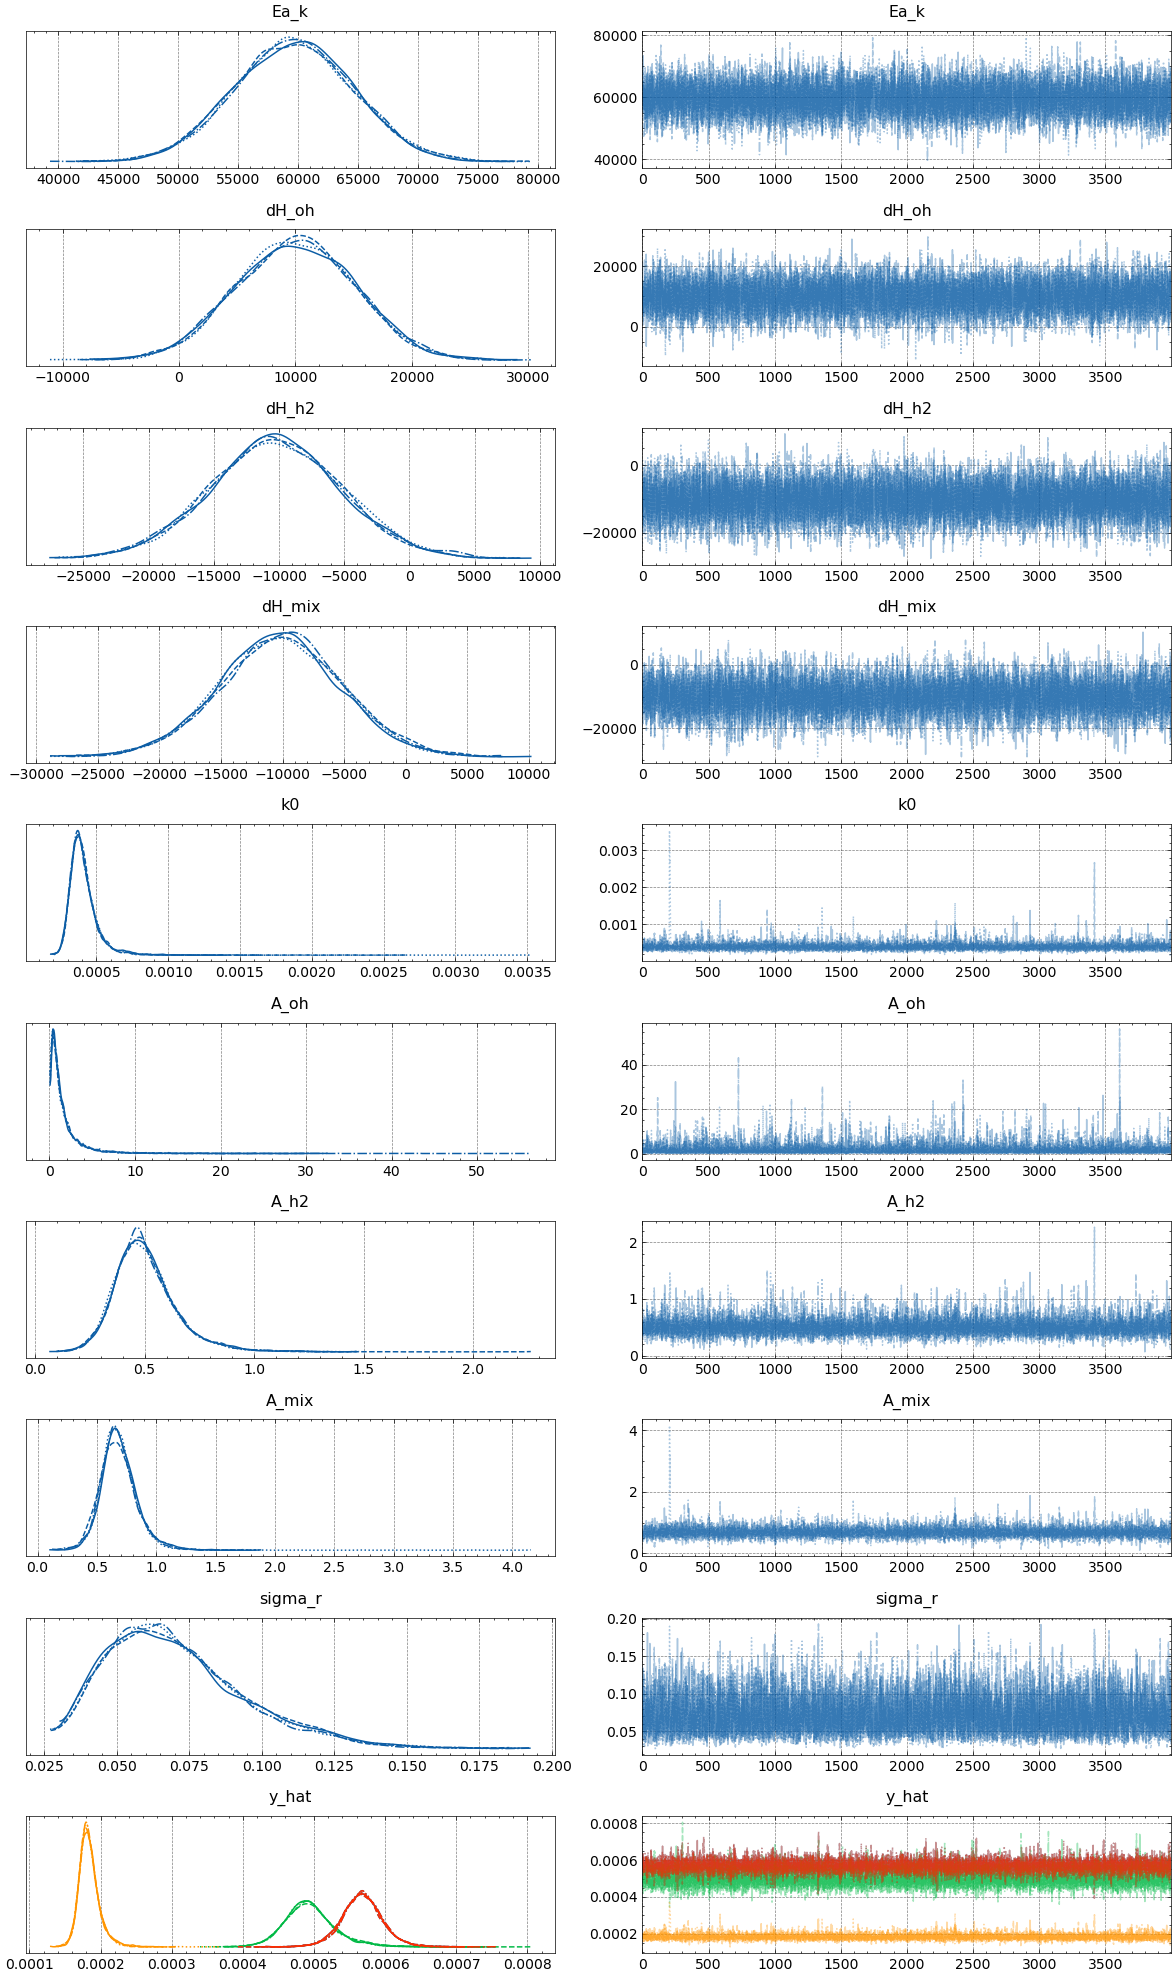

In [49]:
az.plot_trace(idata, divergences=False)
plt.show()

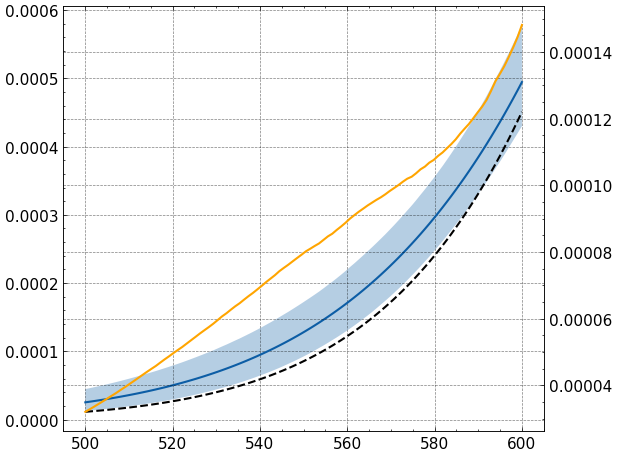

In [50]:
test_res = post_model_over_T(proposals[4], idata, key="posterior")
true_res = true_model_over_T(proposals[4])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [51]:
sol = minimize(
    max_func,
    jnp.array([555.0, 10.0, 1.0, 100, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+00, 5.00000000e-01, 7.72568198e+02,
        3.89163042e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 2.00000000e+00, 1.00000000e+03,
        1.00000000e+00]])

In [52]:
display(pm.summary(idata, hdi_prob=0.95))

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_k,59626.145,4957.221,49654.595,68897.029,49.010,40.209,10223.0,9727.0,1.0
dH_oh,10008.659,5068.657,290.391,19869.029,47.947,40.938,11173.0,10607.0,1.0
dH_h2,-10254.654,5027.098,-20257.588,-490.738,46.384,45.308,11799.0,8138.0,1.0
dH_mix,-10152.188,4957.120,-19975.857,-328.118,51.625,38.934,9209.0,10629.0,1.0
k0,0.000,0.000,0.000,0.001,0.000,0.000,7045.0,5701.0,1.0
A_oh,1.682,2.218,0.033,5.371,0.021,0.079,14691.0,11581.0,1.0
A_h2,0.503,0.146,0.236,0.794,0.002,0.002,7577.0,7204.0,1.0
A_mix,0.685,0.162,0.384,0.993,0.002,0.007,7227.0,6362.0,1.0
sigma_r,0.071,0.024,0.032,0.120,0.000,0.000,5382.0,4264.0,1.0
"y_hat[0, 0]",0.001,0.000,0.001,0.001,0.000,0.000,12144.0,10909.0,1.0
